# Predicting Major Arrival Delays for U.S. Domestic Flights
## ADS 505 Final Team Project, Team 10 Technical Notebook

- **Team:** Allen Ros, Christopher Guillen, Cameron Moran
- **Course:** ADS 505 Applied Data Science for Business, University of San Diego
- **GitHub repository:** https://github.com/aros-usd/ads-505-final-project

In [8]:
# import statements
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlba
from imblearn.over_sampling import SMOTE
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# random seed constant
RANDOM_STATE = 123

# file location
DATA_FILE = 'Data/flights_sample_2025H1.csv'

# Section 1: Problem Statement and Data Description

**Problem:** About one in five U.S. domestic flights arrives late by 15 minutes or more. A delay costs the airline crew time, fuel, and other resources. This can cause further downstream effects like missed connections and later legs flown by the same aircraft. It can also increase overall terminal traffic and passenger dissatisfaction.

**Data Description:** The dataset was taken from the Bureau of Transportation Statistics (BTS). It has one row per non-stop domestic flight leg and 109 fields. We downloaded January through June of 2025 (~3.5 million flights) and sampled 5,000 flights from each month to create a manageable dataset for modeling. We also only selected a subset of 19 columns from the original 109 to reduce the dimensionality of the dataset and to avoid data leakage.

- The dataset was built buy downloading the BTS monthly files for January through June of 2025 and using the `build_sample.py` script to create a random sample of 5,000 flights from each month, creating a 30,000-row dataset.
- Diverted and Cancelled flights were removed, as they have no arrival delay to predict
- 17 of the 19 columns are features and 2 are targets (ArrDel15 and ArrDelayMinutes).

**Objective:** Build and compare classification models that predict whether a scheduled domestic flight will arrive 15 or more minutes late (`ArrDel15 = 1`). The model should also identify which schedule characteristics are most associated with delay.

In [9]:
# load the dataset and view a few rows
flights_df = pd.read_csv(DATA_FILE)
print(f'Dataset shape: {flights_df.shape}')
flights_df.head()

Dataset shape: (30000, 19)


,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,Tail_Number,Origin,OriginState,Dest,DestState,CRSDepTime,DepTimeBlk,CRSArrTime,ArrDelayMinutes,ArrDel15,ArrTimeBlk,CRSElapsedTime,Distance,DistanceGroup
0,1,1,3,2025-01-01,B6,N2044J,JFK,NY,FLL,FL,501,0001-0559,804,0.0,0.0,0800-0859,183.0,1069.0,5
1,1,1,3,2025-01-01,AA,N347TT,ORD,IL,CLT,NC,502,0001-0559,808,0.0,0.0,0800-0859,126.0,599.0,3
2,1,1,3,2025-01-01,OH,N524AE,GRR,MI,DCA,VA,547,0001-0559,738,9.0,0.0,0700-0759,111.0,524.0,3
3,1,1,3,2025-01-01,WN,N8533S,PDX,OR,DEN,CO,550,0001-0559,920,0.0,0.0,0900-0959,150.0,991.0,4
4,1,1,3,2025-01-01,AA,N962NN,MSP,MN,MIA,FL,550,0001-0559,1103,0.0,0.0,1100-1159,253.0,1501.0,7


# Section 2: Exploratory Data Analysis

In [10]:
# start by separating the features and target variables
FEATURE_COLS = [
    "Month",
    "DayofMonth",
    "DayOfWeek",
    "FlightDate",
    "Reporting_Airline",
    "Tail_Number",
    "Origin",
    "Dest",
    "OriginState",
    "DestState",
    "CRSDepTime",
    "DepTimeBlk",
    "CRSArrTime",
    "ArrTimeBlk",
    "CRSElapsedTime",
    "Distance",
    "DistanceGroup",
]
TARGET_COLS = [
    "ArrDelayMinutes", 
    "ArrDel15"
]

*The 17 feature columns describe when a flight is scheduled (date, day, times), who operates it (airline, tail number), and where it flies (airports, states, distance). All of them are known before departure. ArrDel15 is the classification target. ArrDelayMinutes is kept only for context and further predictive modeling not implemented by this project.*

In [35]:
# check overall delay rate of dataset
delay_rate = flights_df['ArrDel15'].mean()
print(f'Overall delay rate: {delay_rate:.4f} ({delay_rate*100:.2f}%)')

Overall delay rate: 0.2191 (21.91%)


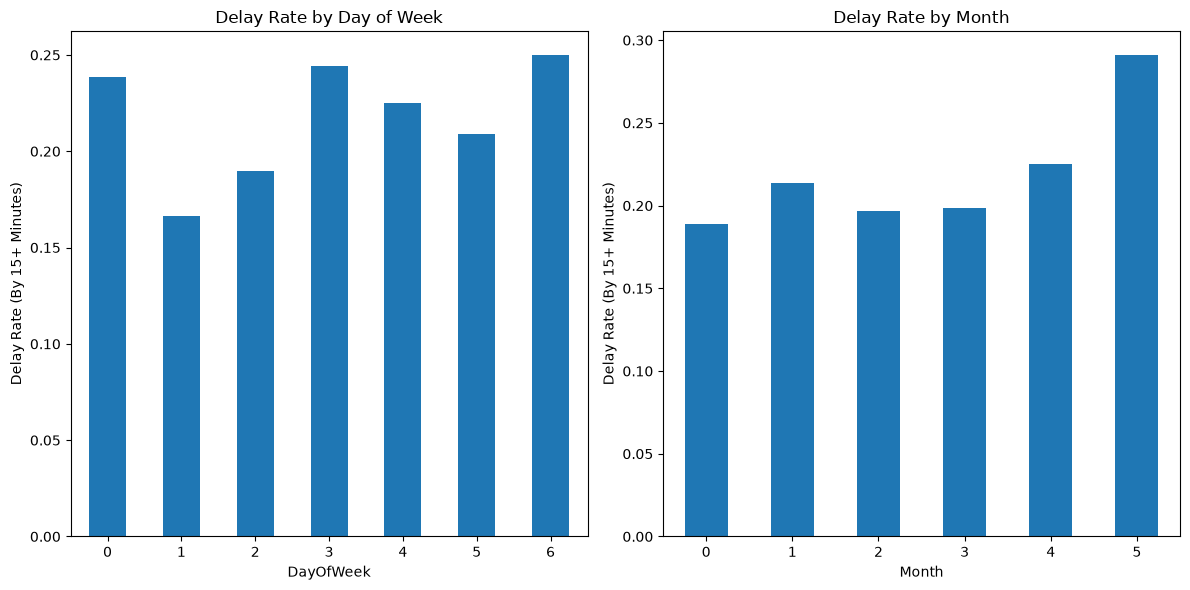

In [36]:
# delay rate by day of week and by month
delay_rate = flights_df['ArrDel15'].mean()
by_day = flights_df.groupby('DayOfWeek')['ArrDel15'].mean()
by_month = flights_df.groupby('Month')['ArrDel15'].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for i, dataset in enumerate([by_day, by_month]):
    dataset.plot(kind='bar', ax=axes[i])
    axes[i].set_ylabel('Delay Rate (By 15+ Minutes)')
    axes[i].set_title(f'Delay Rate by {"Day of Week" if i == 0 else "Month"}')
    axes[i].set_xticklabels(axes[i].get_xticks(), rotation=0)


plt.tight_layout()
plt.show()

*The overall delay rate is ~21.9%. Tuesday (DayOfWeek = 1) is the best day in terms of lowest delay rates (~17%) and Sunday is the worst (~25%). This means there is a very present spread in delay rates across days. There is also a spread across months, with January having the lowest (~18%) and June having the highest (~29%).*

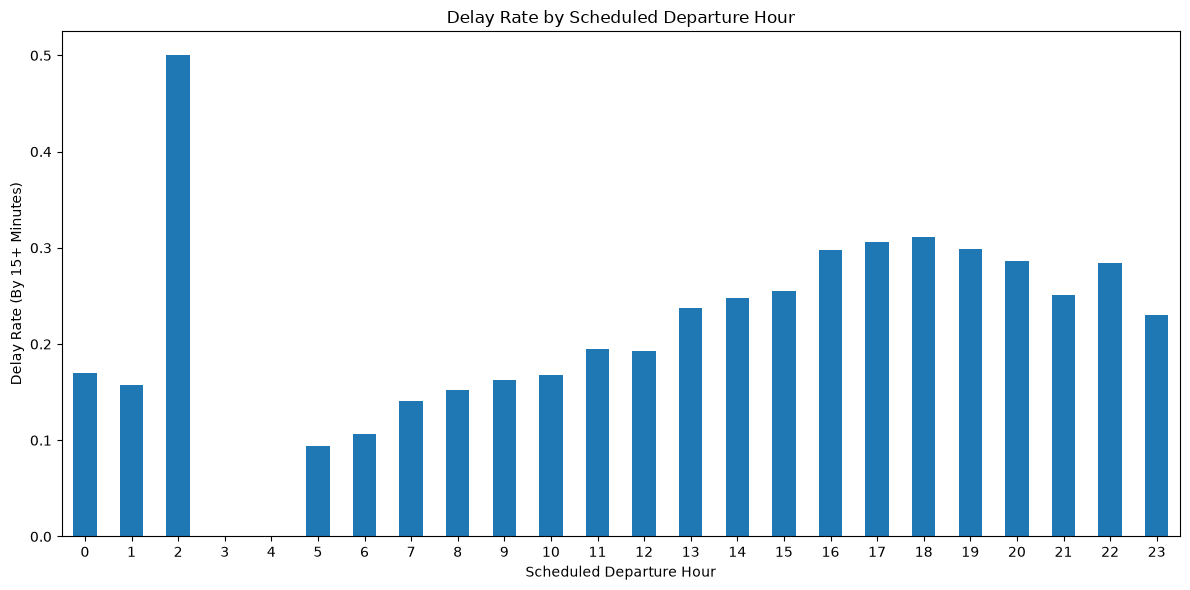

Flights per hour:
CRSDepTime
0       47
1       19
2        2
3        2
4        3
5      882
6     1993
7     2151
8     2077
9     1628
10    1786
11    1978
12    1727
13    1826
14    1788
15    1723
16    1835
17    1918
18    1829
19    1586
20    1354
21     977
22     647
23     222
Name: size, dtype: int64


In [38]:
# delay rate by scheduled departure time (CRSDepTime)
hours_df = flights_df.copy()
hours_df['CRSDepTime'] = hours_df['CRSDepTime'] // 100
hour_stats = hours_df.groupby('CRSDepTime')['ArrDel15'].agg(['mean', 'size'])

fig, ax = plt.subplots(figsize=(12, 6))
hour_stats['mean'].plot(kind='bar', ax=ax)
ax.set_xlabel('Scheduled Departure Hour')
ax.set_ylabel('Delay Rate (By 15+ Minutes)')
ax.set_title('Delay Rate by Scheduled Departure Hour')
ax.set_xticklabels(ax.get_xticks(), rotation=0)

plt.tight_layout()
plt.show()

# print flights per hour as support for the figure
print("Flights per hour:")
print(hour_stats['size'])

*Flights between 0 and 4 AM are very uncommon so their rates may be heavily skewed if any flights are delayed for those times in the sample. Ignoring these and looking strictly at the data from 5 AM onwards, we see a clear pattern. Flights leaving at 5-6 a.m. are delayed about 10% of the time, and the rate climbs steadily through the day to about 30% for 4-8 PM flights. This makes sense as delays early in the day can compound and propagate out to the flights that follow.*

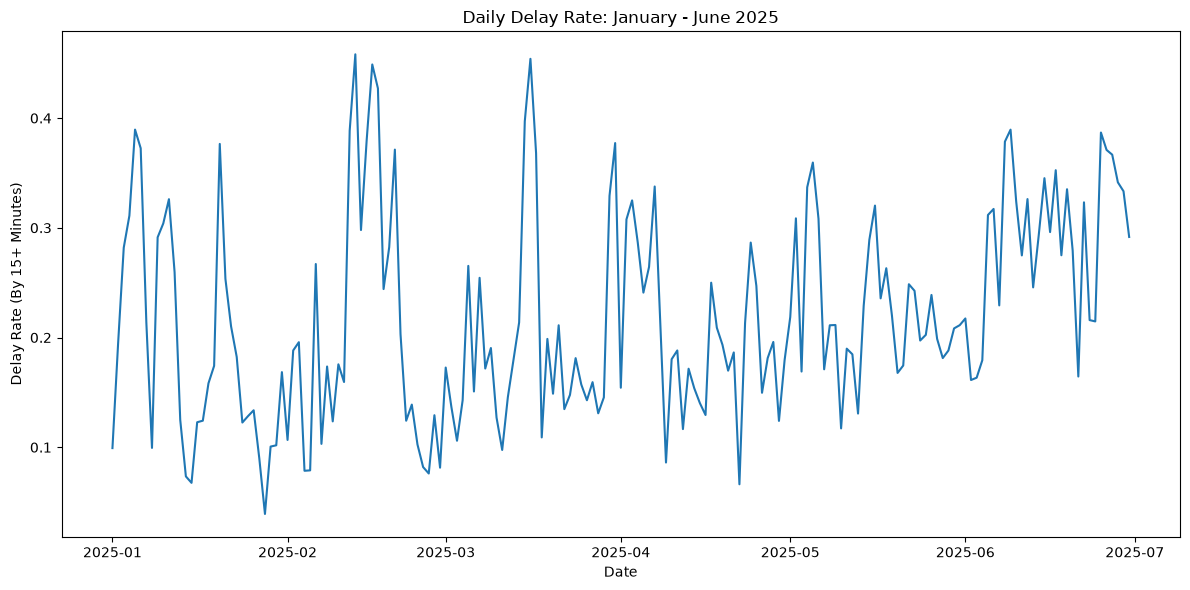

In [ ]:
#
daily_rate = flights_df.groupby('FlightDate')['ArrDel15'].mean()
daily_rate.index = pd.to_datetime(daily_rate.index)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(daily_rate.index, daily_rate.values)
ax.set_title('Daily Delay Rate: January - June 2025')
ax.set_xlabel('Date')
ax.set_ylabel('Delay Rate (By 15+ Minutes)')

plt.tight_layout()
plt.show()

*The daily delay rate is very volatile. It ranges from  ~3-5% to ~45-47%. Fluctuations are likely caused by a variety of factors. Weather delays, aircraft issues, etc. can cause these delays. The goal is to understand underlying patterns and factors that contribute to these delays.*

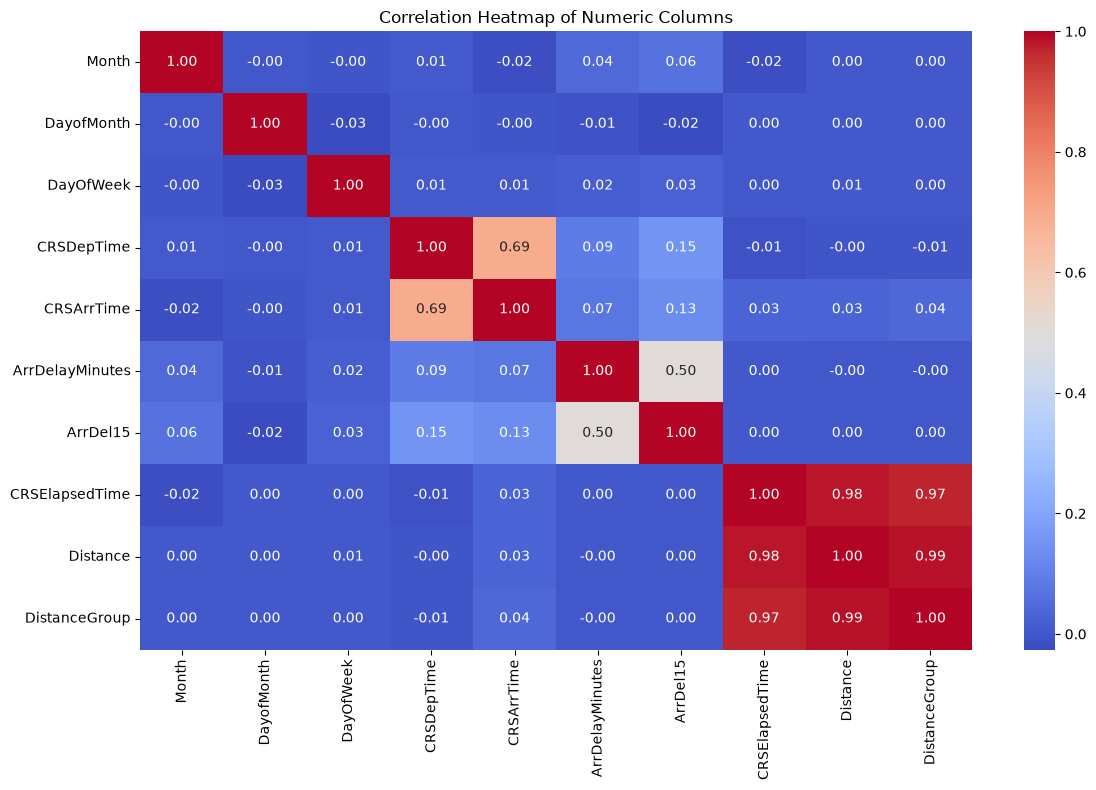

In [33]:
# correlation heatmap of the numeric features and targets
correlations = flights_df.select_dtypes(include='number').corr()

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
ax.set_title('Correlation Heatmap of Numeric Columns')

plt.tight_layout()
plt.show()


- *CRSElapsedTime, Distance, and DistanceGroup are almost perfectly correlated (about 0.97-0.99), because elapsed time is a function of distance. Keeping all three would result in multicollinearity, so Section 3 will handle this by dropping 1 or more of these columns.*

- *CRSDepTime and CRSArrTime are strongly correlated (about 0.68). A flight that departs later usually arrives later, but the correlation is not strong enough to warrant removing one or the other.*

- *The two target columns are strongly correlated with each other, which is to be expected. Every feature has only a weak  correlation with ArrDel15. This does not mean the features will be useless in predictions. The bar charts above show patterns (hour of day, month) that individual features alone cannot capture.*

# Section 3: Data Pre-Processing

In [12]:
# first step is to check for missing values in the dataset
flights_df.isnull().sum()

Month                0
DayofMonth           0
DayOfWeek            0
FlightDate           0
Reporting_Airline    0
Tail_Number          0
Origin               0
OriginState          0
Dest                 0
DestState            0
CRSDepTime           0
DepTimeBlk           0
CRSArrTime           0
ArrDelayMinutes      0
ArrDel15             0
ArrTimeBlk           0
CRSElapsedTime       0
Distance             0
DistanceGroup        0
dtype: int64

In [13]:
# check for outliers using IQR method
# Q1 = flights_df.quantile(0.25)
# Q3 = flights_df.quantile(0.75)
# IQR = Q3 - Q1
# outliers_df = flights_df[((flights_df < (Q1 - 1.5 * IQR)) | (flights_df > (Q3 + 1.5 * IQR))).any(axis=1)]
# print(f'Number of outliers: {outliers_df.shape[0]}')

# Section 4: Data Splitting

# Section 5: Model Building Strategy

# Section 6: Model Performance and Hyperparameter Tuning

# Section 7: Results and Final Model Selection

# Section 8: Discussion and Conclusion